## Part 1

In [39]:
# library imports
import numpy
import pandas as pd
import matplotlib.pyplot as plt

In [50]:
# Load dataset
df = pd.read_csv("bank.csv")
print(df)

       age          job  marital  education default  balance housing loan  \
0       59       admin.  married  secondary      no     2343     yes   no   
1       56       admin.  married  secondary      no       45      no   no   
2       41   technician  married  secondary      no     1270     yes   no   
3       55     services  married  secondary      no     2476     yes   no   
4       54       admin.  married   tertiary      no      184      no   no   
...    ...          ...      ...        ...     ...      ...     ...  ...   
11157   33  blue-collar   single    primary      no        1     yes   no   
11158   39     services  married  secondary      no      733      no   no   
11159   32   technician   single  secondary      no       29      no   no   
11160   43   technician  married  secondary      no        0      no  yes   
11161   34   technician  married  secondary      no        0      no   no   

        contact  day month  duration  campaign  pdays  previous poutcome  \

### 1. Education Distribution & Grouping

In [55]:
# map education level to general level
mapping = {
    'primary': 'basic',
    'secondary': 'intermediate',
    'tertiary': 'higher',
    'unknown': 'not-reported'
}
df['edu_group'] = df['education'].map(mapping)

In [61]:
print(df)

       age          job  marital  education default  balance housing loan  \
0       59       admin.  married  secondary      no     2343     yes   no   
1       56       admin.  married  secondary      no       45      no   no   
2       41   technician  married  secondary      no     1270     yes   no   
3       55     services  married  secondary      no     2476     yes   no   
4       54       admin.  married   tertiary      no      184      no   no   
...    ...          ...      ...        ...     ...      ...     ...  ...   
11157   33  blue-collar   single    primary      no        1     yes   no   
11158   39     services  married  secondary      no      733      no   no   
11159   32   technician   single  secondary      no       29      no   no   
11160   43   technician  married  secondary      no        0      no  yes   
11161   34   technician  married  secondary      no        0      no   no   

        contact  day month  duration  campaign  pdays  previous poutcome  \

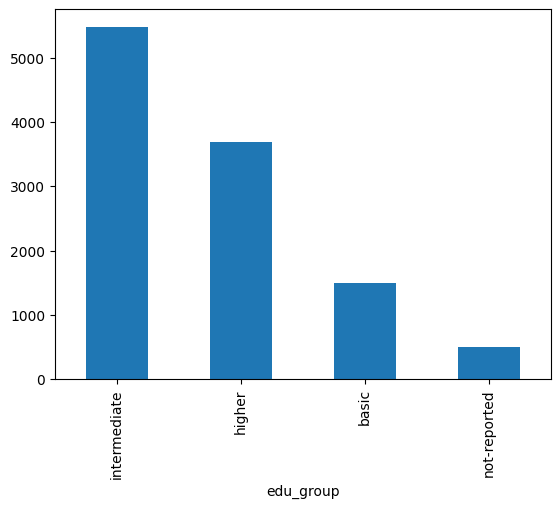

In [65]:
df['edu_group'].value_counts().plot(kind='bar')
plt.show()

Summary:
The graphs show that a large part of the client base has completed intermediate level of education or secondary level.

### 2. Age–Contact Engagement Intensity Relationship and Grouping

In [76]:
# Before grouping: Summary stats
print("\n[Age - Before Grouping]:")
print(df['age'].describe())

print("\n[Duration / Contact Intensity - Before Grouping]:")
print(df['duration'].describe())


[Age - Before Grouping]:
count    11162.000000
mean        41.231948
std         11.913369
min         18.000000
25%         32.000000
50%         39.000000
75%         49.000000
max         95.000000
Name: age, dtype: float64

[Duration / Contact Intensity - Before Grouping]:
count    11162.000000
mean       371.993818
std        347.128386
min          2.000000
25%        138.000000
50%        255.000000
75%        496.000000
max       3881.000000
Name: duration, dtype: float64


In [78]:
# Create basic groups for age and duration
df['age_group'] = pd.cut(df['age'], bins=[0, 30, 50, 100], labels=['young', 'middle-aged', 'senior'])
df['duration_group'] = pd.cut(df['duration'], bins=[0, 100, 250, 500, 10000], labels=['brief', 'standard', 'extended', 'deep-engagement'])

# Print category counts and relationship
print("Age Group Counts:\n", df['age_group'].value_counts())
print("\nDuration Group Counts:\n", df['duration_group'].value_counts())
print("\nRelationship (Cross-tabulation):\n", pd.crosstab(df['age_group'], df['duration_group']))

Age Group Counts:
 age_group
middle-aged    6684
senior         2471
young          2007
Name: count, dtype: int64

Duration Group Counts:
 duration_group
standard           3744
extended           2915
deep-engagement    2766
brief              1737
Name: count, dtype: int64

Relationship (Cross-tabulation):
 duration_group  brief  standard  extended  deep-engagement
age_group                                                 
young             247       685       586              489
middle-aged      1117      2237      1644             1686
senior            373       822       685              591


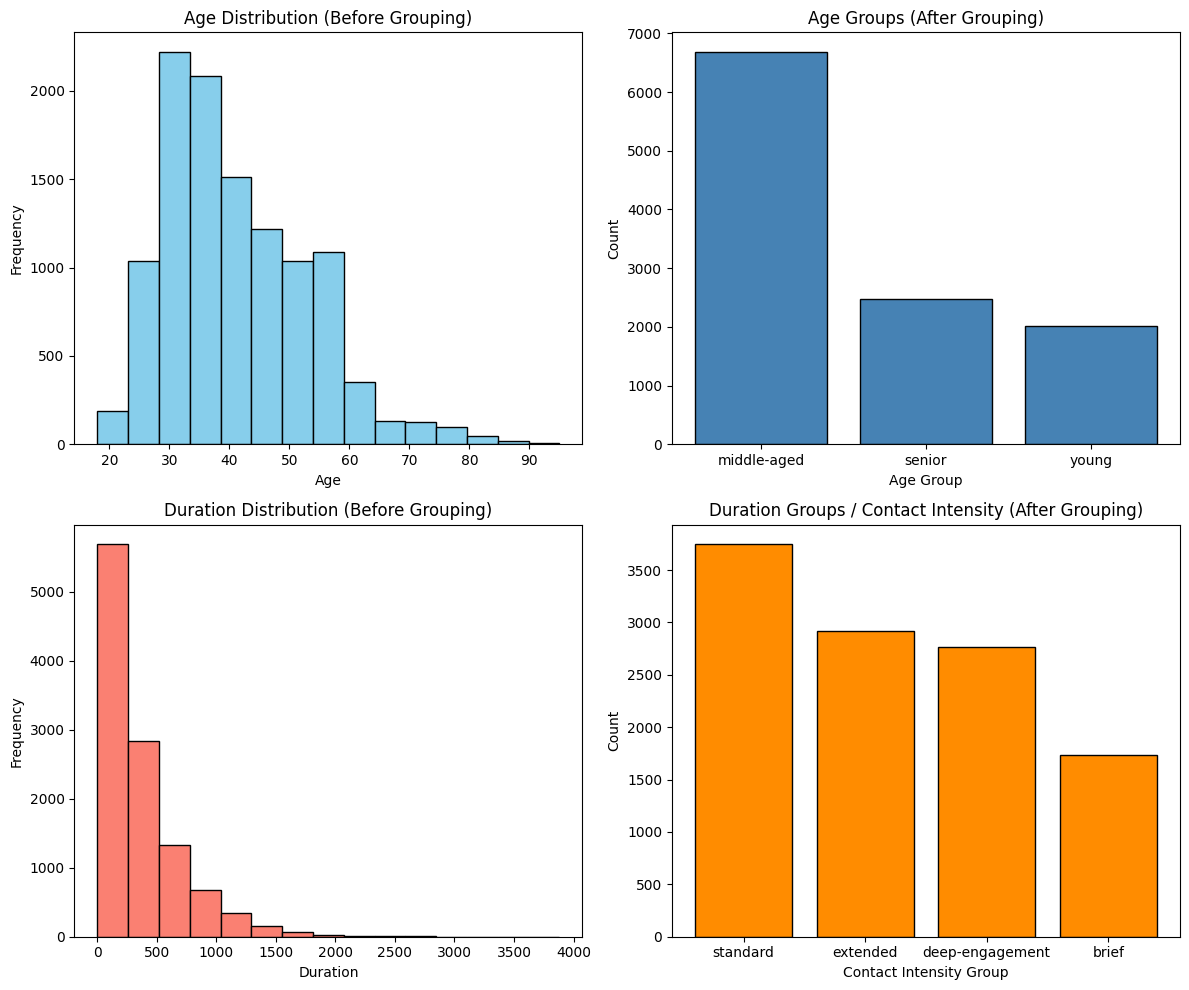

In [80]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# 1. Age: Before grouping (Histogram)
axes[0, 0].hist(df['age'], bins=15, color='skyblue', edgecolor='black')
axes[0, 0].set_title('Age Distribution (Before Grouping)')
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Frequency')

# 2. Age: After grouping (Bar Chart)
age_counts = df['age_group'].value_counts()
axes[0, 1].bar(age_counts.index, age_counts.values, color='steelblue', edgecolor='black')
axes[0, 1].set_title('Age Groups (After Grouping)')
axes[0, 1].set_xlabel('Age Group')
axes[0, 1].set_ylabel('Count')

# 3. Duration: Before grouping (Histogram)
axes[1, 0].hist(df['duration'], bins=15, color='salmon', edgecolor='black')
axes[1, 0].set_title('Duration Distribution (Before Grouping)')
axes[1, 0].set_xlabel('Duration')
axes[1, 0].set_ylabel('Frequency')

# 4. Duration: After grouping (Bar Chart)
dur_counts = df['duration_group'].value_counts()
axes[1, 1].bar(dur_counts.index, dur_counts.values, color='darkorange', edgecolor='black')
axes[1, 1].set_title('Duration Groups / Contact Intensity (After Grouping)')
axes[1, 1].set_xlabel('Contact Intensity Group')
axes[1, 1].set_ylabel('Count')

plt.tight_layout()
plt.show()

Summary:
Grouping continuous data into categorical buckets (like brief, standard, extended, deep-engagement) improves interpretability by allowing clear business insights (e.g., observing which age groups fall into deep-engagement categories via cross-tabulation).

### 3. Account Balance Composition and Group Performance

In [85]:
print("Overall Balance Summary:")
print(df['balance'].describe())

Overall Balance Summary:
count    11162.000000
mean      1528.538524
std       3225.413326
min      -6847.000000
25%        122.000000
50%        550.000000
75%       1708.000000
max      81204.000000
Name: balance, dtype: float64


In [125]:
# Proportions: Zero vs Positive vs Negative
total_clients = len(df)
zero_balance = (df['balance'] == 0).sum()
positive_balance = (df['balance'] > 0).sum()
negative_balance = (df['balance'] < 0).sum()
df['balance_category'] = pd.cut(df['balance'], bins=[-float('inf'), -1, 0.001, float('inf')], labels=['negative', 'zero', 'positive'])

print(f"\nProportion of Clients:")
print(f"Zero Balance (No Capital Activity): {zero_balance} ({zero_balance/total_clients*100:.2f}%)")
print(f"Positive Balance (Gain-like): {positive_balance} ({positive_balance/total_clients*100:.2f}%)")
print(f"Negative Balance (Loss-like): {negative_balance} ({negative_balance/total_clients*100:.2f}%)")

# Non-zero balance distribution stats
print("\nNon-Zero Balance Summary:")
print(df[df['balance'] != 0]['balance'].describe())


Proportion of Clients:
Zero Balance (No Capital Activity): 774 (6.93%)
Positive Balance (Gain-like): 9700 (86.90%)
Negative Balance (Loss-like): 688 (6.16%)

Non-Zero Balance Summary:
count    10388.000000
mean      1642.428475
std       3315.332708
min      -6847.000000
25%        192.000000
50%        638.000000
75%       1854.000000
max      81204.000000
Name: balance, dtype: float64


In [97]:
# age group comparison
age_comparison = df.groupby('age_group').agg(
    mean_balance=('balance', 'mean'),
    nonzero_proportion=('balance', lambda x: (x != 0).mean() * 100)
)
print(age_comparison)

# duration group comparison
duration_comparison = df.groupby('duration_group').agg(
    mean_balance=('balance', 'mean'),
    nonzero_proportion=('balance', lambda x: (x != 0).mean() * 100)
)
print(duration_comparison)

             mean_balance  nonzero_proportion
age_group                                    
young         1201.563029           95.964126
middle-aged   1416.980850           92.414722
senior        2095.876163           92.472683
                 mean_balance  nonzero_proportion
duration_group                                   
brief             1305.944732           91.479562
standard          1461.182692           92.922009
extended          1660.399314           94.133791
deep-engagement   1620.531092           93.130875


C:\Users\MOIESHA\AppData\Local\Temp\ipykernel_37180\4056812088.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_comparison = df.groupby('age_group').agg(
C:\Users\MOIESHA\AppData\Local\Temp\ipykernel_37180\4056812088.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  duration_comparison = df.groupby('duration_group').agg(


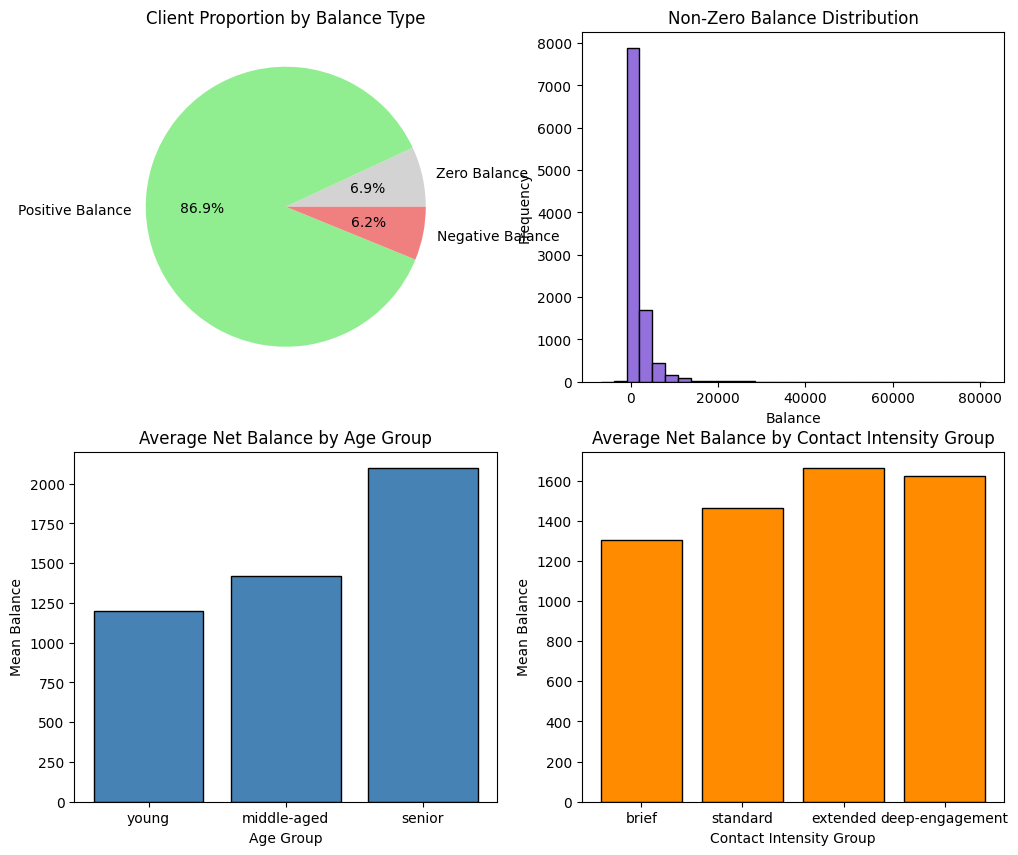

In [143]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# 1. Balance Composition (Pie Chart)
categories = ['Zero Balance', 'Positive Balance', 'Negative Balance']
counts = [zero_balance, positive_balance, negative_balance]
axes[0, 0].pie(counts, labels=categories, autopct='%1.1f%%', colors=['lightgray', 'lightgreen', 'lightcoral'])
axes[0, 0].set_title('Client Proportion by Balance Type')

# 2. Non-Zero Balance Distribution (Histogram)
nonzero_vals = df[df['balance'] != 0]['balance']
axes[0, 1].hist(nonzero_vals, bins=30, color='mediumpurple', edgecolor='black')
axes[0, 1].set_title('Non-Zero Balance Distribution')
axes[0, 1].set_xlabel('Balance')
axes[0, 1].set_ylabel('Frequency')

# 3. Mean Balance by Age Group (Bar Chart)
axes[1, 0].bar(age_comparison.index, age_comparison['mean_balance'], color='steelblue', edgecolor='black')
axes[1, 0].set_title('Average Net Balance by Age Group')
axes[1, 0].set_xlabel('Age Group')
axes[1, 0].set_ylabel('Mean Balance')

# 4. Mean Balance by Duration Group (Bar Chart)
axes[1, 1].bar(duration_comparison.index, duration_comparison['mean_balance'], color='darkorange', edgecolor='black')
axes[1, 1].set_title('Average Net Balance by Contact Intensity Group')
axes[1, 1].set_xlabel('Contact Intensity Group')
axes[1, 1].set_ylabel('Mean Balance')

plt.show()

Summary:
1. Balance Composition:The analysis shows that a vast majority of clients hold a positive balance , while a small fraction hold negative balances or exactly zero balance. 
2. Age vs. Contact Intensity Association: Comparing group metrics revealed that the mojority of wealth is concentrated with the more senior citizns. Similarly, contact intensity categories show how longer call durations depends on client financial profiles.
3. Impact of Grouping on Interpretability: Discretizing continuous data into grouped categories makes it easy to present distinct client bases to business stakeholders (e.g., comparing senior vs. young financial profiles directly). thus improving interpretatbility.

### 4. Final Dataset Refinement and Structure

In [130]:
d = pd.read_csv('bank.csv')
print(f"Original dataset shape (Rows, Columns): {d.shape}")

# Check missing values before processing
print("\nMissing values per column (Before):")
print(d.isnull().sum())

print(f"\nRefined dataset shape (Rows, Columns): {df.shape}")
print("\nNewly created features: 'age_group', 'duration_group'")
print(df.isnull().sum())

Original dataset shape (Rows, Columns): (11162, 17)

Missing values per column (Before):
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

Refined dataset shape (Rows, Columns): (11162, 20)

Newly created features: 'age_group', 'duration_group'
age                 0
job                 0
marital             0
education           0
default             0
balance             0
housing             0
loan                0
contact             0
day                 0
month               0
duration            0
campaign            0
pdays               0
previous            0
poutcome            0
deposit             0
age_group           0
duration_group      0
balance_category    0
dtype: int64


In [132]:
# Before and After comparison
print("\n--- Age vs Age Group ---")
print("Before (Sample continuous stats):")
print(df['age'].describe()[['min', 'mean', 'max']])
print("After (Group counts):")
print(df['age_group'].value_counts())

print("\n--- Duration vs Duration Group ---")
print("Before (Sample continuous stats):")
print(df['duration'].describe()[['min', 'mean', 'max']])
print("After (Group counts):")
print(df['duration_group'].value_counts())


--- Age vs Age Group ---
Before (Sample continuous stats):
min     18.000000
mean    41.231948
max     95.000000
Name: age, dtype: float64
After (Group counts):
age_group
middle-aged    6684
senior         2471
young          2007
Name: count, dtype: int64

--- Duration vs Duration Group ---
Before (Sample continuous stats):
min        2.000000
mean     371.993818
max     3881.000000
Name: duration, dtype: float64
After (Group counts):
duration_group
standard           3744
extended           2915
deep-engagement    2766
brief              1737
Name: count, dtype: int64


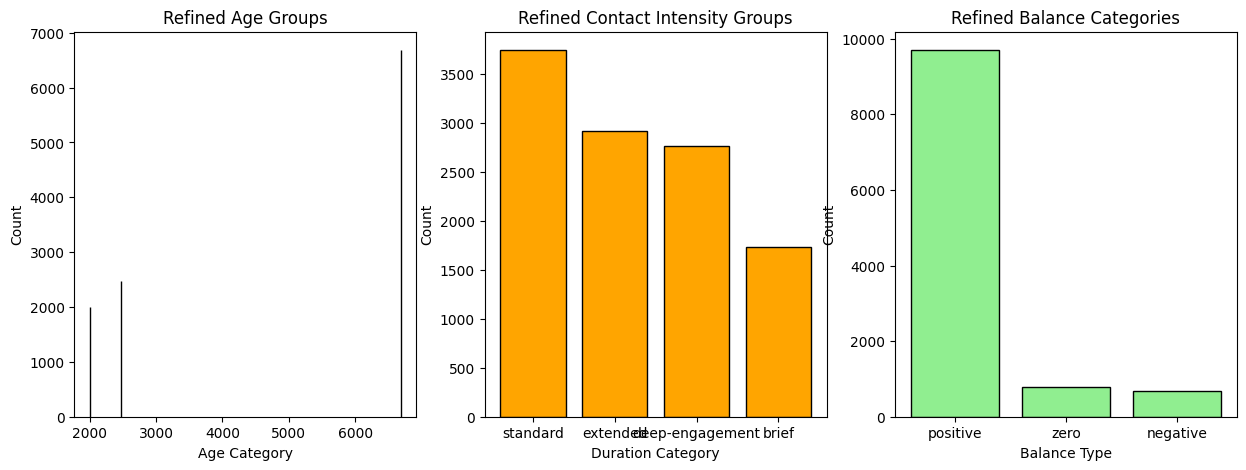

In [153]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))

# 1. Age Groups Bar Chart
age_counts = df['age_group'].value_counts()
ax1.bar(age_counts, age_counts.values, color='skyblue', edgecolor='black')
ax1.set_title('Refined Age Groups')
ax1.set_xlabel('Age Category')
ax1.set_ylabel('Count')

# 2. Duration Groups Bar Chart
dur_counts = df['duration_group'].value_counts()
ax2.bar(dur_counts.index, dur_counts.values, color='orange', edgecolor='black')
ax2.set_title('Refined Contact Intensity Groups')
ax2.set_xlabel('Duration Category')
ax2.set_ylabel('Count')

# 3. Balance Categories Bar Chart
bal_counts = df['balance_category'].value_counts()
ax3.bar(bal_counts.index, bal_counts.values, color='lightgreen', edgecolor='black')
ax3.set_title('Refined Balance Categories')
ax3.set_xlabel('Balance Type')
ax3.set_ylabel('Count')

plt.show()

Summary of Refined Dataset Structure:
1. Created Features include transformed continuous variables into discrete bins (age_group, duration_group, and balance_category).
2. Missing/Unknown Values were checked via .isnull().sum(). Standard cleaning ensures no unhandled missing values distort the modeling phase.